In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import os

In [6]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/espectros_swir_351_1.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
output_path = os.path.join(output_dir, 'espectros_correction_msc.csv')

In [7]:
df = pd.read_csv(input_path)
data = df.values
data

array([[1.000e+00, 2.929e+03, 2.871e+03, ..., 2.791e+03, 2.843e+03,
        2.961e+03],
       [0.000e+00, 2.689e+03, 2.735e+03, ..., 2.601e+03, 2.641e+03,
        2.622e+03],
       [2.906e+03, 2.952e+03, 2.910e+03, ..., 3.000e+03, 2.788e+03,
        2.901e+03],
       ...,
       [2.811e+03, 2.861e+03, 2.862e+03, ..., 2.829e+03, 2.777e+03,
        2.767e+03],
       [3.145e+03, 3.032e+03, 3.036e+03, ..., 2.956e+03, 3.024e+03,
        3.227e+03],
       [2.639e+03, 2.572e+03, 2.597e+03, ..., 2.491e+03, 2.386e+03,
        2.363e+03]], shape=(92480, 256))

In [8]:
# Calcula o espectro de referência (média das amostras)
espectro_referencia = np.mean(data, axis=0).reshape(-1, 1)
bandas_corrigidas = np.zeros_like(data)

In [9]:
# Aplica a correção MSC
for i in range(data.shape[0]):
    amostra = data[i, :].reshape(-1, 1)
    modelo = LinearRegression().fit(espectro_referencia, amostra)
    inclinacao = modelo.coef_[0][0]
    intercepto = modelo.intercept_[0]
    bandas_corrigidas[i, :] = (data[i, :] - intercepto) / inclinacao
    
df_espectros = pd.DataFrame(bandas_corrigidas, columns=df.columns)
df_espectros.head()

,Banda_0,Banda_1,Banda_2,Banda_3,Banda_4,Banda_5,Banda_6,Banda_7,Banda_8,Banda_9,...,Banda_246,Banda_247,Banda_248,Banda_249,Banda_250,Banda_251,Banda_252,Banda_253,Banda_254,Banda_255
0,-6820.579425,3579.051997,3373.048369,3532.878770,3539.982344,3309.116209,3383.703729,3408.566236,3056.939354,3678.502024,...,2925.523247,2840.280366,2723.071405,2914.867887,2996.558980,2861.591086,3145.734021,3088.905434,3273.598342,3692.709171
1,-5533.143963,3413.823805,3566.877177,3570.204424,3427.132793,3686.658076,3287.388410,3437.114535,3267.424927,3546.913693,...,2665.193181,2868.155261,2601.975484,2715.101889,3124.353297,2851.519025,2605.302731,3121.026049,3254.115938,3190.898241
2,3430.117080,3604.979809,3445.322534,3441.521171,3205.836622,3243.850259,3190.631168,3011.967074,3008.165711,2954.946619,...,2080.632972,1863.955242,2590.015706,2723.063435,2335.324339,2810.494799,2704.056616,3787.445266,2981.556165,3411.110261
3,3852.329685,3573.599405,2847.433673,2840.098666,2950.123777,4981.920823,3228.854057,3650.616982,3507.584338,2979.463806,...,2436.673260,2521.025845,2425.670749,2752.078577,2609.045933,2253.298075,2381.660704,3016.138843,2623.715948,3386.556716
4,3445.413318,3613.254424,3323.996348,3413.273532,3409.702445,3270.430038,3149.013067,3238.290251,3448.984406,3331.138523,...,2331.234061,2524.072779,2220.530353,2206.246003,2391.942546,2409.797983,2484.790818,2677.629535,3102.588932,3409.702445


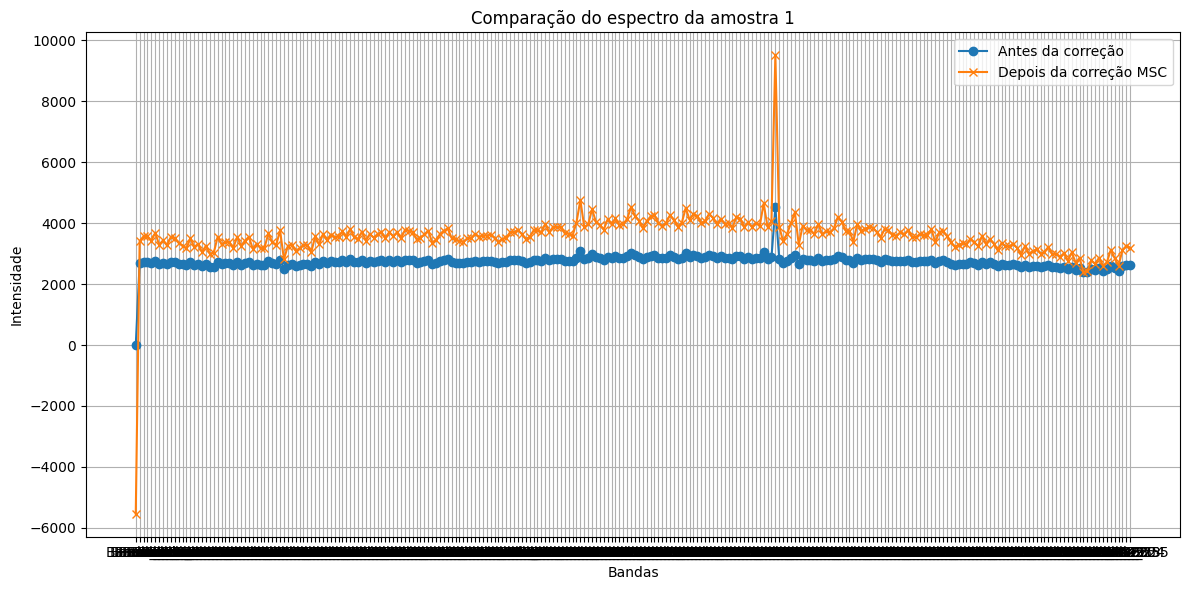

In [13]:
indice_amostra = df.shape[0] - 1

plt.figure(figsize=(12, 6))
plt.plot(df.columns, df.iloc[indice_amostra, :], label='Antes da correção', marker='o')
plt.plot(df.columns, df_espectros.iloc[indice_amostra, :], label='Depois da correção MSC', marker='x')
plt.xlabel('Bandas')
plt.ylabel('Intensidade')
plt.title(f'Comparação do espectro da amostra {indice_amostra}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
df_espectros.to_csv(output_path, index=False)
print("Arquivo corrigido salvo com sucesso em:\n", output_path)